# 2013 — Deep Q-Networks (DQN): Deep Reinforcement Learning

**Papers:** Volodymyr Mnih et al., *"Playing Atari with Deep Reinforcement Learning"* (2013); *"Human-level control through deep reinforcement learning"* (Nature, 2015). Builds on Q-learning (Watkins, 1989) and TD-Gammon (Tesauro, 1992).

Reinforcement learning has no labels: an **agent** acts in an **environment** and receives **rewards**. Q-learning learns the value of each action, $Q(s,a)$ = expected discounted future reward, from the **Bellman equation**:

$$Q(s,a) \leftarrow r + \gamma \max_{a'} Q(s', a')$$

DQN used a **neural network** for $Q$ and learned 49 Atari games from raw pixels with a single architecture. Two tricks made neural Q-learning stable:
- **Experience replay:** store transitions in a buffer and train on random mini-batches, which breaks the correlation between consecutive steps
- **Target network:** compute the target $r + \gamma \max_{a'} Q_{\bar\theta}(s',a')$ with a slowly updated copy $\bar\theta$, so the target doesn't move with every update

The same ideas, actor-critic methods and PPO led to AlphaGo (2016) and, much later, the RL stage of LLM training (notebooks 58 and 69).

**Environment:** CartPole (balance a pole on a cart). The physics are written out below, so no `gym` install is needed. The networks here are tiny and the agent acts one step at a time, so this notebook **deliberately runs on CPU**, which is faster than a GPU for this workload.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
import copy
from collections import deque
device = torch.device("cpu")      # tiny networks, one step at a time: CPU beats GPU here
torch.set_num_threads(1)

PyTorch 2.15.0 | device: mps


In [2]:
class CartPole:
    """Classic cart-pole (Barto, Sutton & Anderson 1983), same constants as OpenAI Gym's CartPole-v1."""
    g, m_cart, m_pole, half_len, force, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, seed=0): self.rng = np.random.default_rng(seed)
    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, 4); self.t = 0; return self.s.astype(np.float32)
    def step(self, action):
        x, x_dot, th, th_dot = self.s
        f = self.force if action == 1 else -self.force
        total, pml = self.m_cart + self.m_pole, self.m_pole * self.half_len
        tmp = (f + pml * th_dot ** 2 * math.sin(th)) / total
        th_acc = (self.g * math.sin(th) - math.cos(th) * tmp) / (self.half_len * (4 / 3 - self.m_pole * math.cos(th) ** 2 / total))
        x_acc = tmp - pml * th_acc * math.cos(th) / total
        self.s = np.array([x + self.dt * x_dot, x_dot + self.dt * x_acc, th + self.dt * th_dot, th_dot + self.dt * th_acc])
        self.t += 1
        failed = abs(self.s[0]) > 2.4 or abs(self.s[2]) > 12 * math.pi / 180
        return self.s.astype(np.float32), 1.0, failed, self.t >= 500        # obs, reward, terminated, truncated

env = CartPole()
s, steps = env.reset(), 0
while True:
    s, r, term, trunc = env.step(np.random.randint(2)); steps += 1
    if term or trunc: break
print("a random policy keeps the pole up for", steps, "steps (the maximum is 500)")

a random policy keeps the pole up for 12 steps (the maximum is 500)


In [3]:
def q_net(): return nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))

def train_dqn(episodes=300, replay=True, target_net=True, seed=0):
    seed_everything(seed); env = CartPole(seed)
    q = q_net(); q_target = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=1e-3)
    buffer = deque(maxlen=50_000)
    gamma, batch, total_steps, returns = 0.99, 64, 0, []
    for ep in range(episodes):
        s, ep_ret = env.reset(), 0.0
        while True:
            eps = max(0.05, 1.0 - total_steps / 10_000)                             # epsilon-greedy exploration
            if random.random() < eps: a = random.randrange(2)
            else:
                with torch.no_grad(): a = q(torch.from_numpy(s)).argmax().item()
            s2, r, term, trunc = env.step(a); ep_ret += r; total_steps += 1
            buffer.append((s, a, r, s2, float(term)))
            s = s2
            if len(buffer) >= 1000:
                sample = random.sample(buffer, batch) if replay else list(buffer)[-batch:]   # no replay: most recent steps only
                S, A, R, S2, D = (torch.tensor(np.array(x)) for x in zip(*sample))
                with torch.no_grad():
                    nxt = (q_target if target_net else q)(S2).max(1).values
                    target = R.float() + gamma * (1 - D.float()) * nxt                     # Bellman target
                pred = q(S).gather(1, A.long()[:, None]).squeeze(1)
                loss = F.smooth_l1_loss(pred, target)                                      # Huber loss, as in DQN
                opt.zero_grad(); loss.backward(); opt.step()
                if total_steps % 500 == 0: q_target.load_state_dict(q.state_dict())     # periodic target sync
            if term or trunc: break
        returns.append(ep_ret)
    return q, returns

t0 = time.time()
q, rets = train_dqn()
print(f"DQN trained in {time.time() - t0:.0f}s | mean return of last 20 episodes: {np.mean(rets[-20:]):.0f}")

DQN trained in 18s | mean return of last 20 episodes: 209


## Ablation: remove replay and the target network
The same network trained online on the latest steps against a moving target. Learning is much less stable.

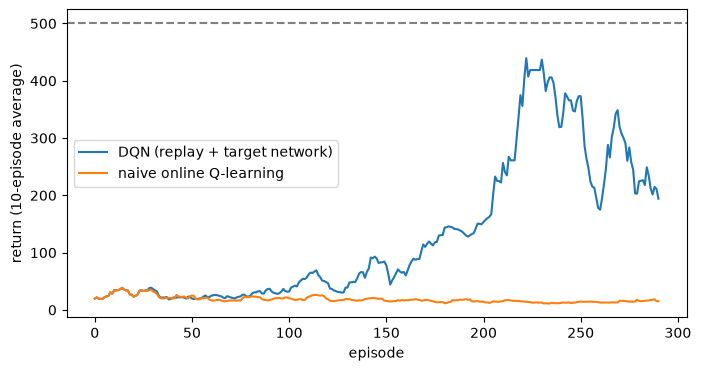

In [4]:
_, rets_naive = train_dqn(replay=False, target_net=False)
smooth = lambda r: np.convolve(r, np.ones(10) / 10, mode="valid")
plt.figure(figsize=(8, 4))
plt.plot(smooth(rets), label="DQN (replay + target network)"); plt.plot(smooth(rets_naive), label="naive online Q-learning")
plt.axhline(500, ls="--", c="gray"); plt.xlabel("episode"); plt.ylabel("return (10-episode average)"); plt.legend(); plt.show()

## Evaluating the greedy policy

greedy returns over 10 new episodes: [500.0, 500.0, 500.0, 480.0, 500.0, 500.0, 500.0, 415.0, 401.0, 500.0]


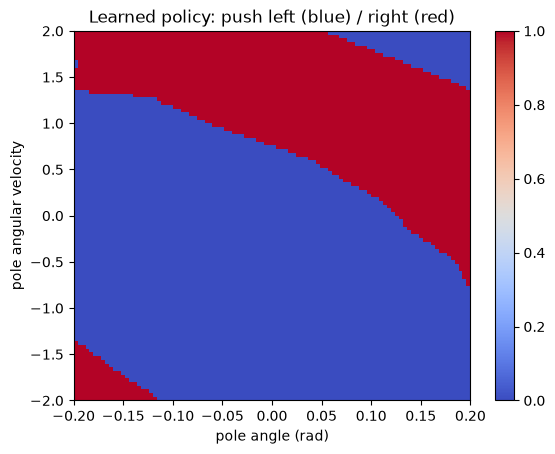

In [5]:
def evaluate(q, n=10):
    out = []
    for i in range(n):
        env = CartPole(seed=100 + i); s, total = env.reset(), 0
        while True:
            with torch.no_grad(): s, r, term, trunc = env.step(q(torch.from_numpy(s)).argmax().item())
            total += r
            if term or trunc: break
        out.append(total)
    return out
print("greedy returns over 10 new episodes:", evaluate(q))

xs = np.linspace(-0.2, 0.2, 100); ws = np.linspace(-2, 2, 100)
grid = torch.tensor([[0, 0, a, w] for w in ws for a in xs], dtype=torch.float32)
with torch.no_grad(): pol = q(grid).argmax(1).view(100, 100)
plt.imshow(pol, extent=[-0.2, 0.2, -2, 2], aspect="auto", origin="lower", cmap="coolwarm")
plt.xlabel("pole angle (rad)"); plt.ylabel("pole angular velocity"); plt.title("Learned policy: push left (blue) / right (red)"); plt.colorbar(); plt.show()